# 5. Modelo final y evaluación en el hold-out temporal

**Objetivo del capítulo.** Elegir la estrategia de validación final, reentrenar el MLP con toda la serie
previa al hold-out y medir **una sola vez** su desempeño en el tramo reservado (≈ 10 % final), que no participó
en la validación cruzada, ni en la búsqueda de arquitectura, ni en el ajuste de los escaladores. Se guardan los
modelos por horizonte que usa la API (capítulo de despliegue).

**Reglas para no contaminar el hold-out.** El lag que se despliega para cada horizonte se elige con el error de
**validación** de la estrategia final, nunca con el hold-out. El hold-out de las 16 configuraciones se muestra
solo como evidencia.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import joblib
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from fcst.cv import STRATEGY_LABEL
from fcst.experiments import fit_final, load_preds, parse_arch, write_json
from fcst.features import holdout_split
from fcst.metrics import bds_pvalue
from fcst.nbutils import INK2, MODEL_COLOR, MUTED, PART_COLOR, plt, savefig, setup

cfg, RES, FIG = setup()
APP = cfg.path("app_dir")
series = pd.read_csv(RES / "serie_modelado.csv", parse_dates=["Date"])
y, dates = series.Close.values, series.Date
sp = holdout_split(len(y), cfg["holdout_frac"], cfg["horizons"])
LAGS, HS = cfg["lags"], cfg["horizons"]
best = pd.read_csv(RES / "mejor_arquitectura.csv")
pf = pd.read_csv(RES / "cv_metricas_por_fold.csv")
cons = pd.read_csv(RES / "consolidado_lag_h.csv")

Perfil: full  |  resultados en: /content/deep-learning-02-forecasting-mlp/results


## 5.1 Estrategia de validación final

Se adopta **Forward Chaining**: es la única de las tres que entrena siempre con el pasado y valida en el futuro
inmediato, igual que en el uso real del modelo (capítulo 2). Group K-Fold y K-Fold mezclan entrenamiento
posterior a la validación, de modo que su error es una estimación optimista o, como mínimo, no comparable con lo
que el modelo enfrentará en producción.

In [2]:
FINAL = "forwardChaining"
fc = cons[cons.estrategia == FINAL]
chosen = fc.loc[fc.groupby("H").RMSE.idxmin(), ["H", "lag", "RMSE", "MAPE"]].rename(
    columns={"RMSE": "RMSE_val", "MAPE": "MAPE_val"}).reset_index(drop=True)
chosen = chosen.merge(best[["lag", "H", "arquitectura", "dropout_mask", "best_epoch"]], on=["lag", "H"])
display(Markdown("**Lag elegido para cada horizonte** (menor RMSE medio de validación en Forward Chaining):"))
chosen

**Lag elegido para cada horizonte** (menor RMSE medio de validación en Forward Chaining):

,H,lag,RMSE_val,MAPE_val,arquitectura,dropout_mask,best_epoch
0,7,21,4035.175287,6.373751,"(64, 128, 256)","(False, False, True)",7
1,14,7,6647.052940,9.389017,"(256, 256)","(False, True)",8
2,21,7,6337.056343,9.619889,"(256, 256)","(True, True)",4
3,28,7,7491.821846,10.301693,"(256, 256, 64)","(False, False, False)",4


## 5.2 Reentrenamiento con toda la serie de CV y evaluación en el hold-out (16 configuraciones)

In [3]:
final = {}
rows = []
for lag in LAGS:
    for H in HS:
        b = best.query("lag == @lag and H == @H").iloc[0]
        ep = int(min(max(b.best_epoch, 1), cfg["train"]["epochs_max"]))
        m, sc, res = fit_final(y, sp.n_cv, lag, H, parse_arch(b.arquitectura), parse_arch(b.dropout_mask), ep, cfg,
                               seed=cfg["seed"])
        final[(lag, H)] = (m, sc, res)
        sm, sn = res["summary_mlp"], res["summary_naive"]
        rows.append({"lag": lag, "H": H, "arquitectura": b.arquitectura, "RMSE_hold": sm["RMSE"], "MAPE_hold": sm["MAPE"],
                     "MAE_hold": sm["MAE"], "MSE_hold": sm["MSE"], "BDS_pvalue_h1_hold": sm["BDS_pvalue_h1"],
                     "RMSE_naive_hold": sn["RMSE"], "MAPE_naive_hold": sn["MAPE"],
                     "desplegado": bool(((chosen.lag == lag) & (chosen.H == H)).any())})
np.savez_compressed(RES / "preds" / "holdout_final.npz", **{
    f"l{lag}_h{H}__{k}": final[(lag, H)][2][k] for (lag, H) in final for k in ["hold_idx", "y_hold", "p_hold", "p_naive"]})
hold = pd.DataFrame(rows)
hold["MLP_mejor_que_ingenuo"] = hold.RMSE_hold < hold.RMSE_naive_hold
hold.to_csv(RES / "holdout_16_configuraciones.csv", index=False)
hold.style.format({"RMSE_hold": "{:,.0f}", "MAPE_hold": "{:.2f}", "MAE_hold": "{:,.0f}", "MSE_hold": "{:.3e}",
                   "BDS_pvalue_h1_hold": "{:.3f}", "RMSE_naive_hold": "{:,.0f}", "MAPE_naive_hold": "{:.2f}"}).hide(axis="index")

lag,H,arquitectura,RMSE_hold,MAPE_hold,MAE_hold,MSE_hold,BDS_pvalue_h1_hold,RMSE_naive_hold,MAPE_naive_hold,desplegado,MLP_mejor_que_ingenuo
7,7,"(64, 256)","4,450",4.98,"3,539",2.041e+07,0.000,"3,217",3.06,False,False
7,14,"(256, 256)","4,823",5.06,"3,668",2.447e+07,0.000,"4,539",4.35,True,False
7,21,"(256, 256)","5,901",6.17,"4,434",3.777e+07,0.000,"5,695",5.57,True,False
7,28,"(256, 256, 64)","7,047",7.43,"5,524",5.194e+07,0.000,"6,717",6.69,True,False
14,7,"(64, 128, 256)","4,086",4.38,"3,146",1.780e+07,0.000,"3,217",3.06,False,False
14,14,"(128, 256)","5,059",5.26,"3,852",2.653e+07,0.000,"4,539",4.35,False,False
14,21,"(256, 128, 128)","6,308",6.67,"5,040",4.087e+07,0.000,"5,695",5.57,False,False
14,28,"(256, 256)","6,507",6.92,"5,064",4.515e+07,0.000,"6,717",6.69,False,True
21,7,"(64, 128, 256)","5,343",6.05,"4,272",2.879e+07,0.000,"3,217",3.06,True,False
21,14,"(64, 128, 256)","5,843",6.12,"4,656",3.452e+07,0.000,"4,539",4.35,False,False


## 5.3 Modelos desplegados (uno por horizonte)

In [4]:
card = {"generado_con_perfil": cfg.profile, "simbolo": cfg["data"]["symbol"], "variable": cfg["target"],
        "estrategia_validacion": STRATEGY_LABEL[FINAL],
        "entrenamiento": {"desde": str(dates.iloc[0].date()), "hasta": str(dates.iloc[sp.n_cv - 1].date())},
        "holdout": {"desde": str(dates.iloc[sp.n_cv].date()), "hasta": str(dates.iloc[-1].date())}, "horizontes": {}}
dep = []
for r in chosen.itertuples():
    m, sc, res = final[(r.lag, r.H)]
    m.save(APP / f"model_h{r.H}.keras")
    joblib.dump({"x": sc.x, "y": sc.y}, APP / f"scalers_h{r.H}.joblib")
    h = hold.query("lag == @r.lag and H == @r.H").iloc[0]
    card["horizontes"][str(r.H)] = {"lags": int(r.lag), "arquitectura": r.arquitectura, "dropout_mask": r.dropout_mask,
                                    "epocas": int(r.best_epoch), "RMSE_val_USD": float(r.RMSE_val),
                                    "MAPE_val_pct": float(r.MAPE_val), "RMSE_holdout_USD": float(h.RMSE_hold),
                                    "MAPE_holdout_pct": float(h.MAPE_hold), "RMSE_ingenuo_holdout_USD": float(h.RMSE_naive_hold)}
    dep.append({"H": r.H, "lag": r.lag, "arquitectura": r.arquitectura, "RMSE val (FC)": r.RMSE_val,
                "RMSE hold-out": h.RMSE_hold, "RMSE ingenuo hold-out": h.RMSE_naive_hold,
                "MAPE hold-out": h.MAPE_hold, "MAPE ingenuo hold-out": h.MAPE_naive_hold})
card["ultimo_cierre_conocido"] = {"fecha": str(dates.iloc[-1].date()), "close": float(y[-1])}
card["ultimos_cierres"] = [float(v) for v in y[-max(LAGS):]]
write_json(card, APP / "model_card.json")
dep = pd.DataFrame(dep)
dep.to_csv(RES / "modelos_desplegados.csv", index=False)
print("Modelos guardados en", APP)
dep.style.format({c: "{:,.0f}" for c in dep.columns if "RMSE" in c} | {c: "{:.2f}" for c in dep.columns if "MAPE" in c}).hide(axis="index")

Modelos guardados en /content/deep-learning-02-forecasting-mlp/app


H,lag,arquitectura,RMSE val (FC),RMSE hold-out,RMSE ingenuo hold-out,MAPE hold-out,MAPE ingenuo hold-out
7,21,"(64, 128, 256)","4,035","5,343","3,217",6.05,3.06
14,7,"(256, 256)","6,647","4,823","4,539",5.06,4.35
21,7,"(256, 256)","6,337","5,901","5,695",6.17,5.57
28,7,"(256, 256, 64)","7,492","7,047","6,717",7.43,6.69


## 5.4 Error por paso del horizonte en el hold-out: MLP frente al ingenuo

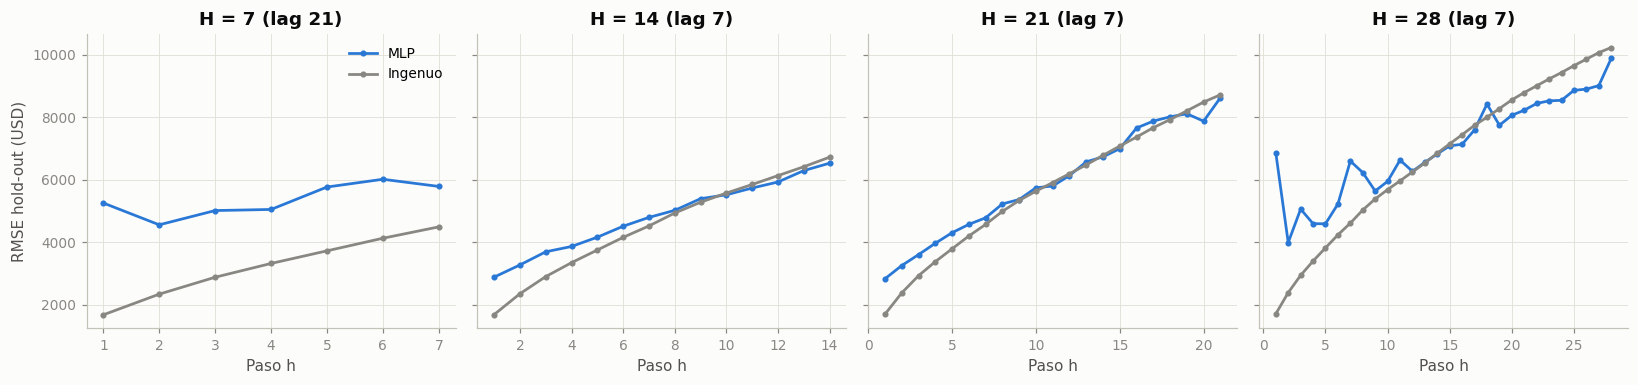

In [5]:
fig, axes = plt.subplots(1, len(HS), figsize=(15, 3.6), sharey=True)
for ax, r in zip(axes, chosen.itertuples()):
    res = final[(r.lag, r.H)][2]
    ax.plot(res["per_h_mlp"].h, res["per_h_mlp"].RMSE, marker=".", color=MODEL_COLOR["mlp"], label="MLP")
    ax.plot(res["per_h_naive"].h, res["per_h_naive"].RMSE, marker=".", color=MODEL_COLOR["naive"], label="Ingenuo")
    ax.set_title(f"H = {r.H} (lag {r.lag})"); ax.set_xlabel("Paso h")
axes[0].set_ylabel("RMSE hold-out (USD)"); axes[0].legend()
savefig(fig, FIG, "05_holdout_rmse_por_paso")
plt.show()

## 5.5 Serie real frente a predicha: entrenamiento, validación y hold-out

Para cada (lag, H): las tres columnas muestran el **mejor, el mediano y el peor** fold de Forward Chaining
(por RMSE de validación); la cuarta, el modelo final en el hold-out. Se grafica la predicción a un paso (h = 1)
en la fecha que pronostica, y en el hold-out también la de h = H.

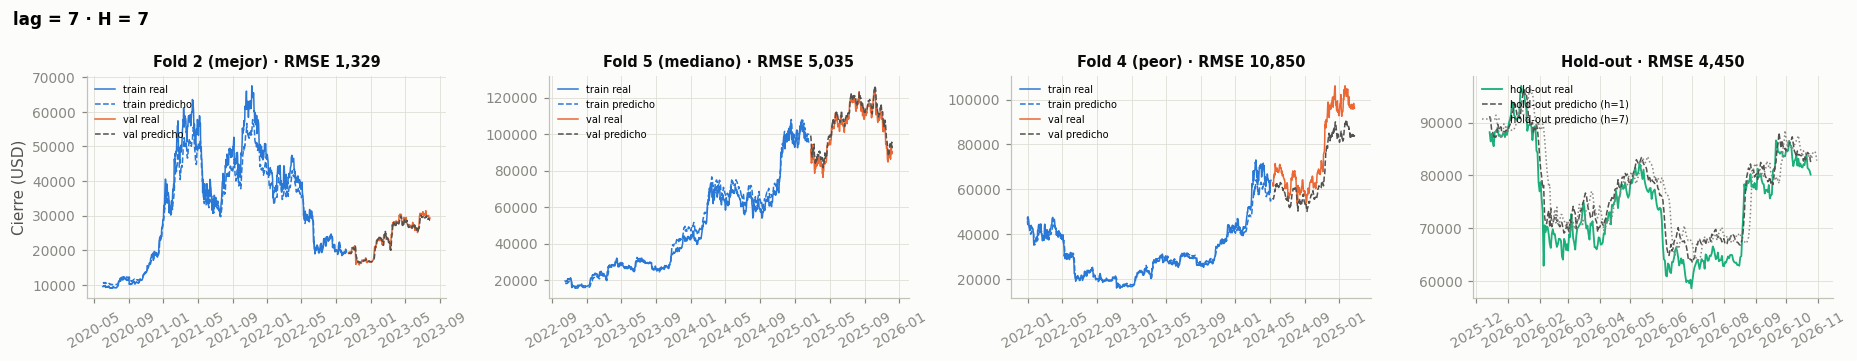

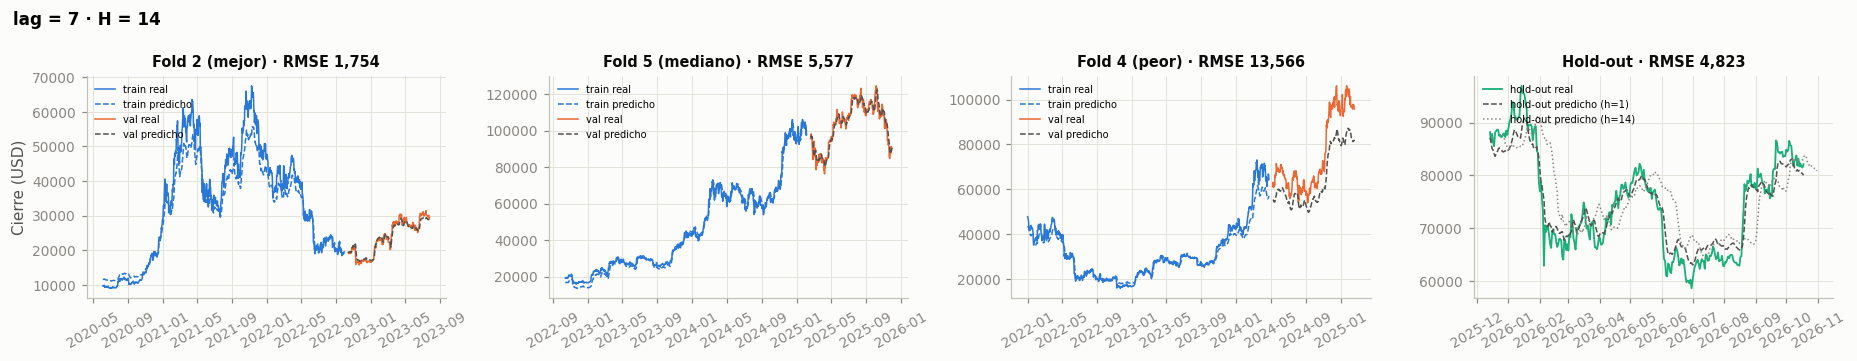

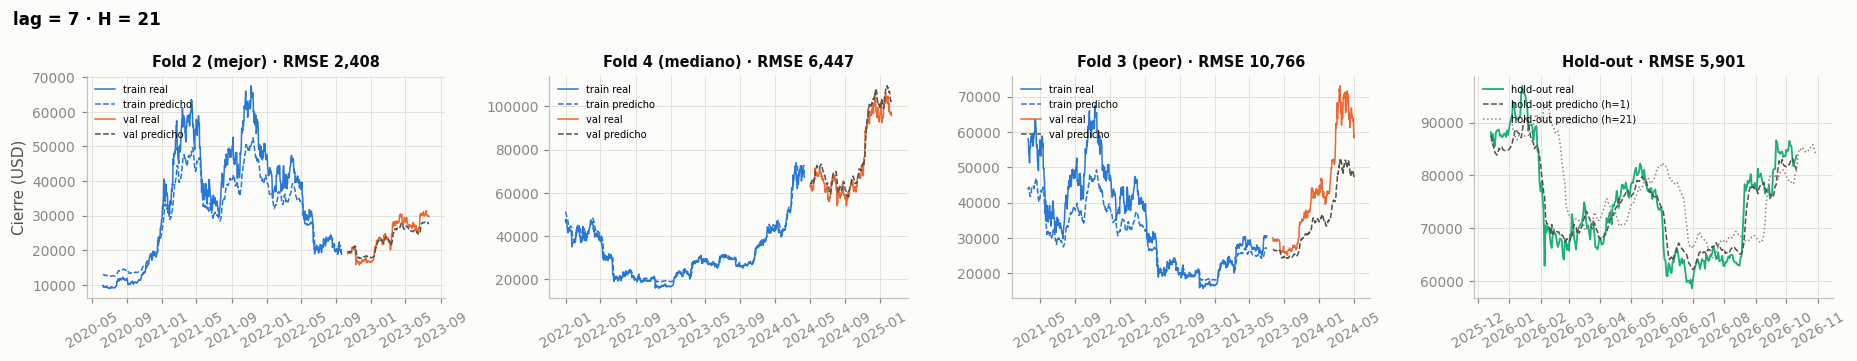

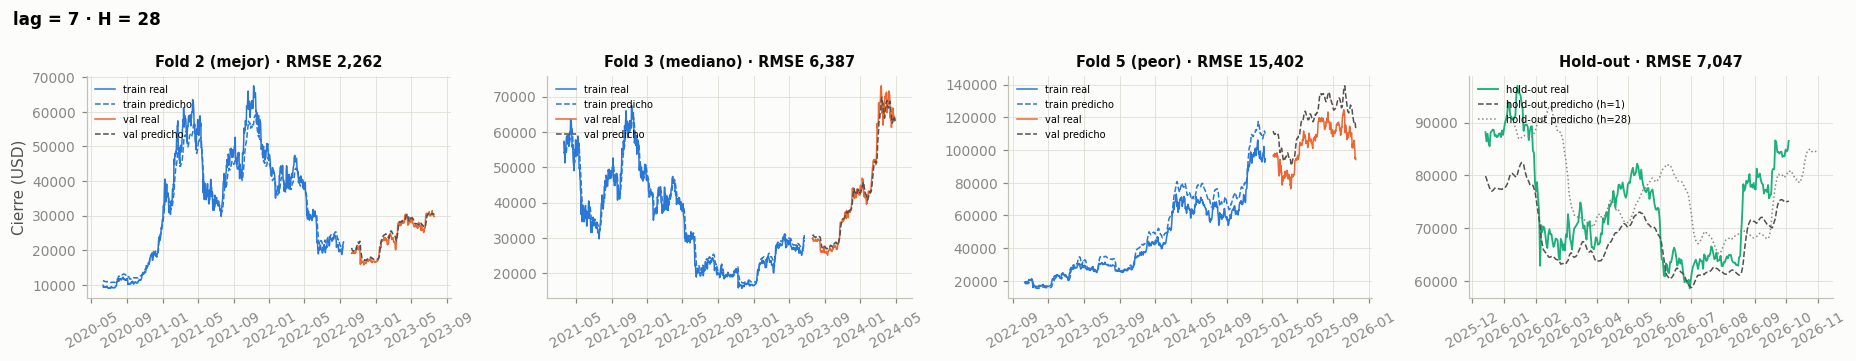

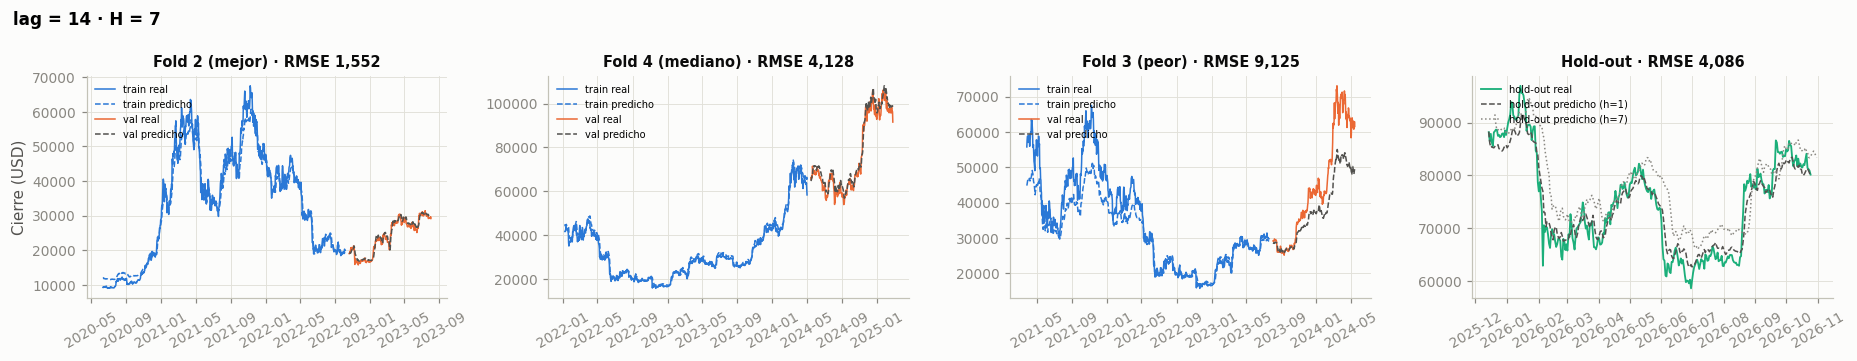

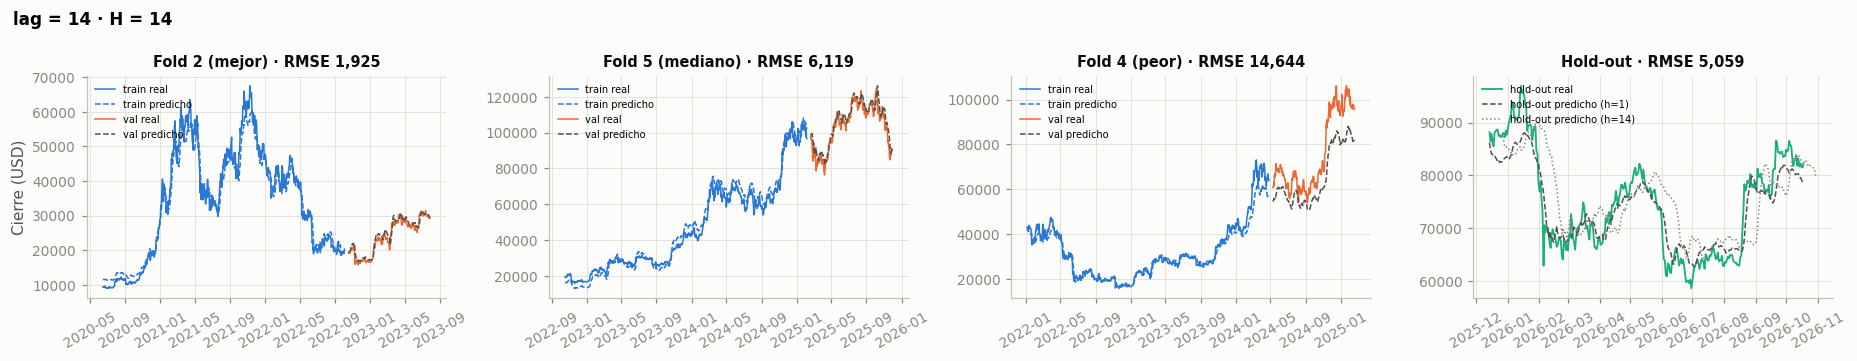

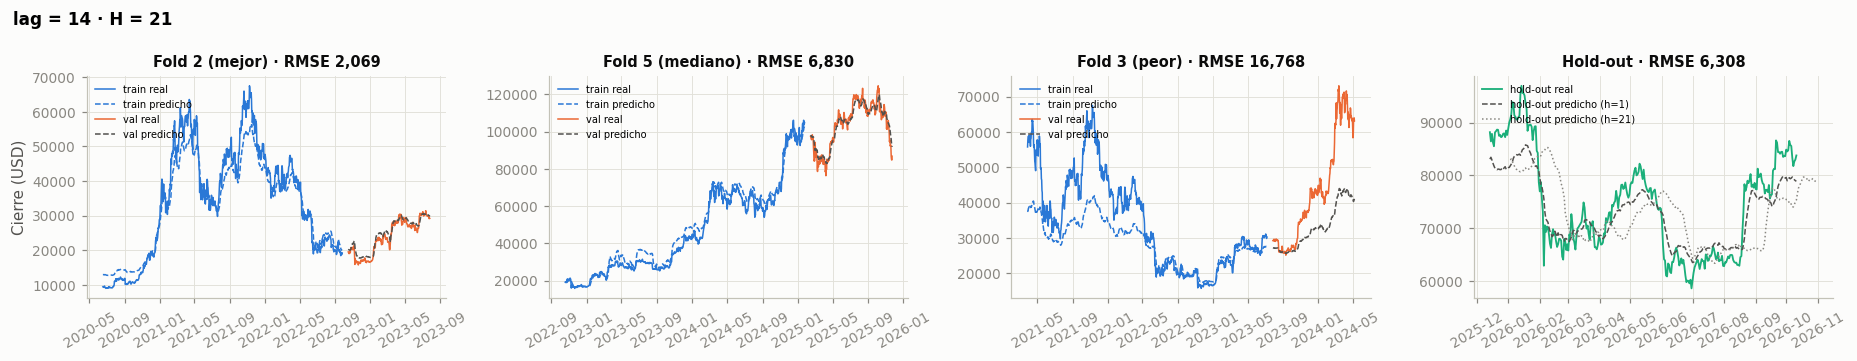

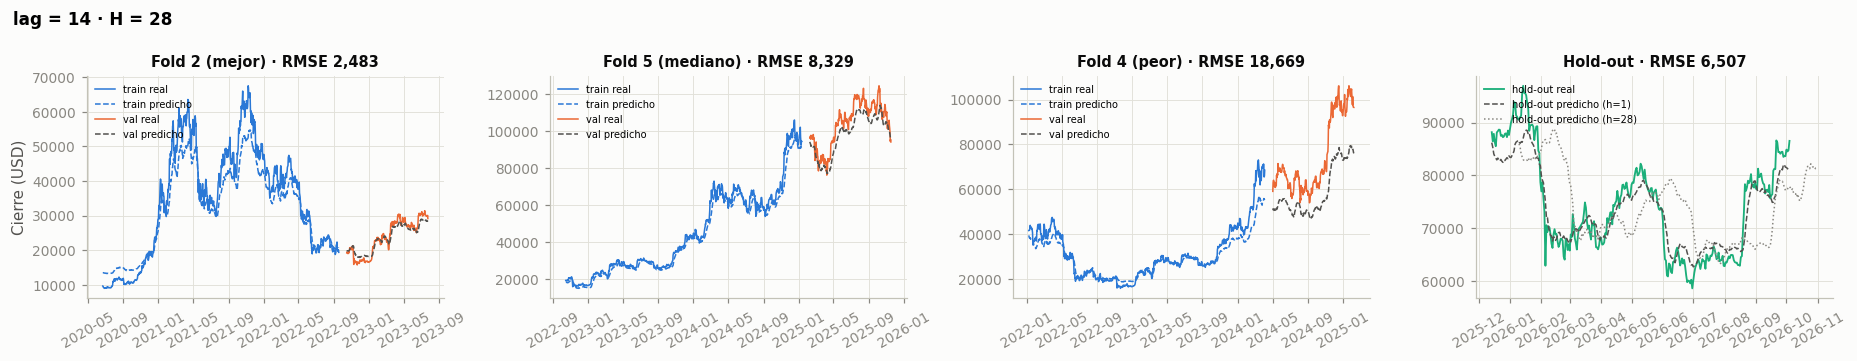

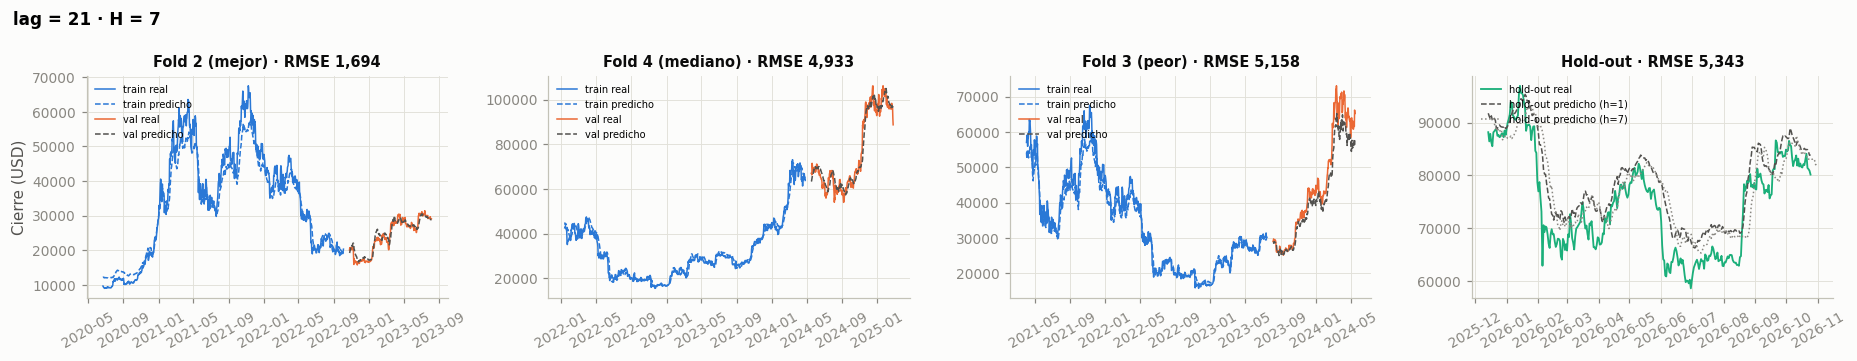

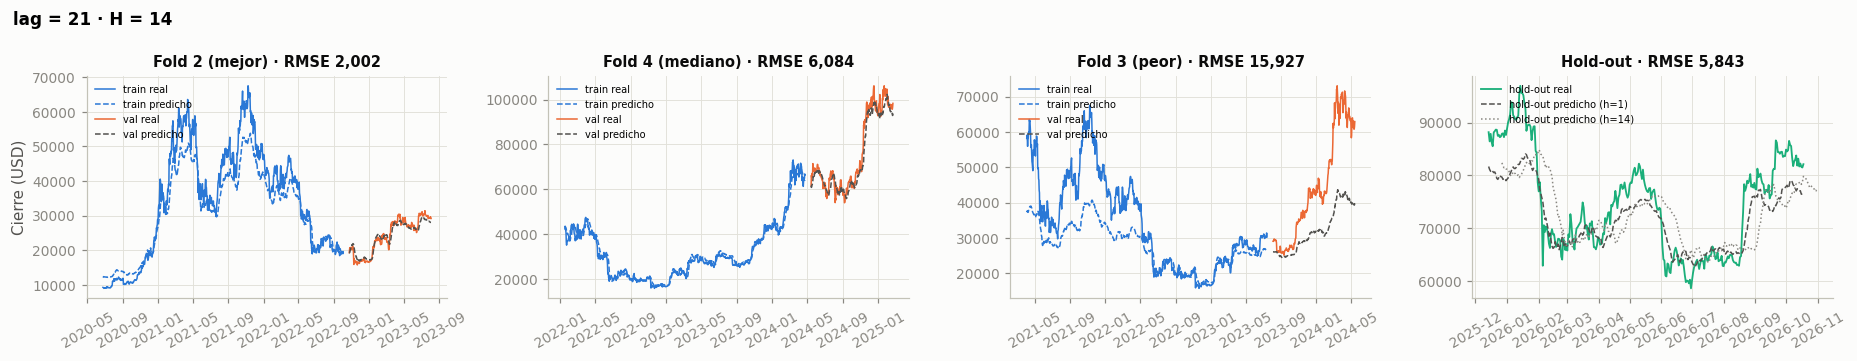

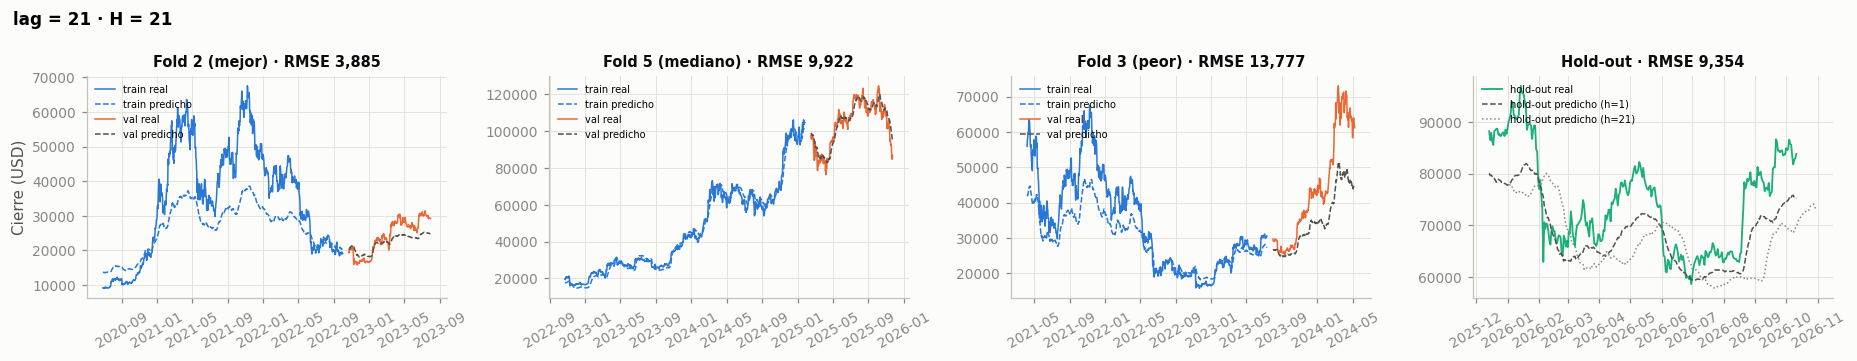

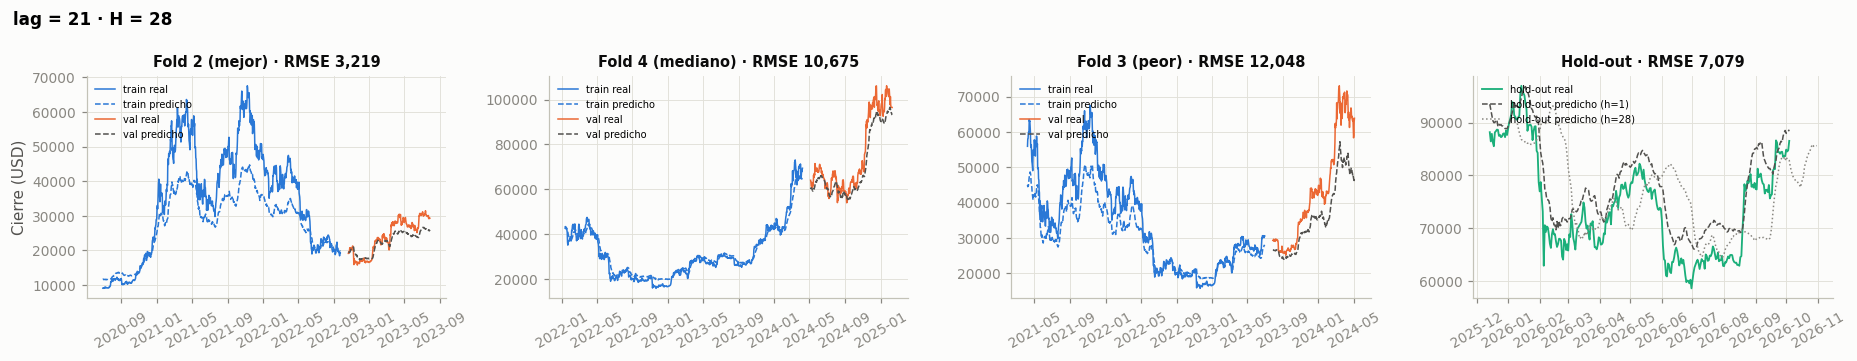

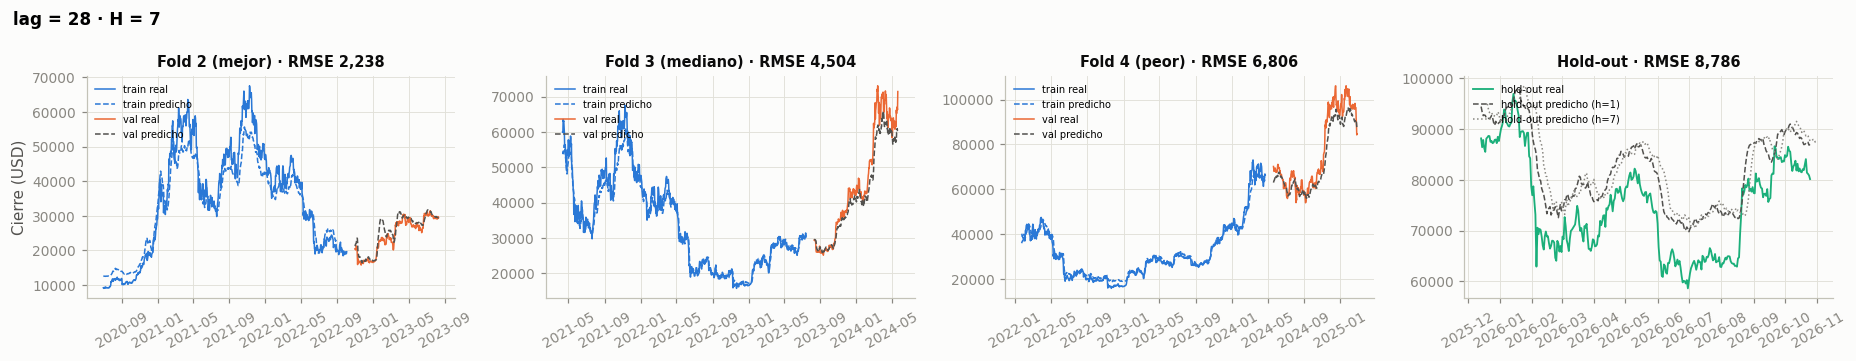

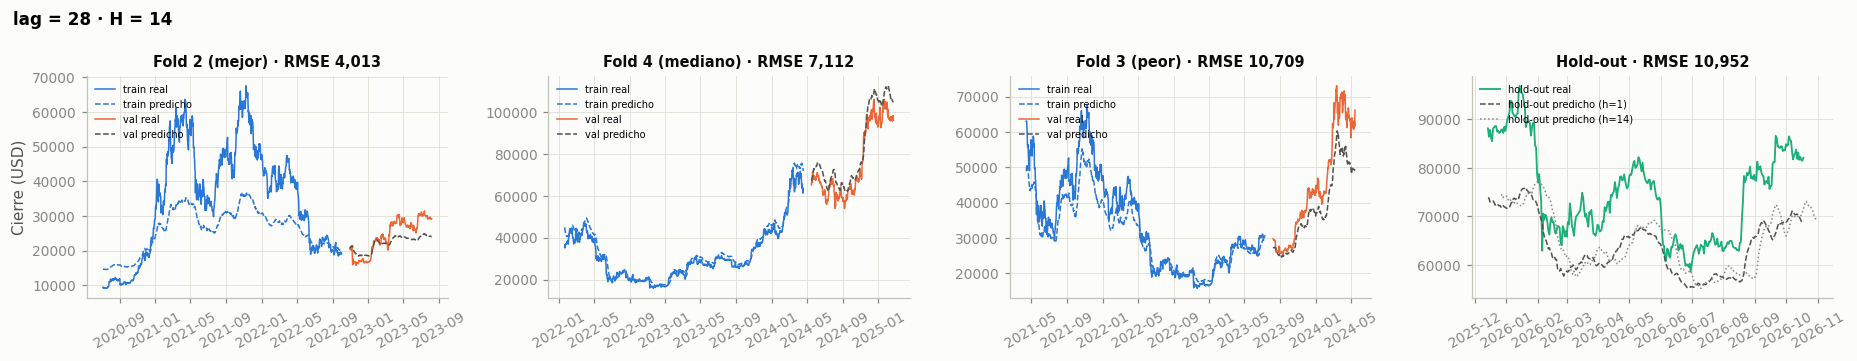

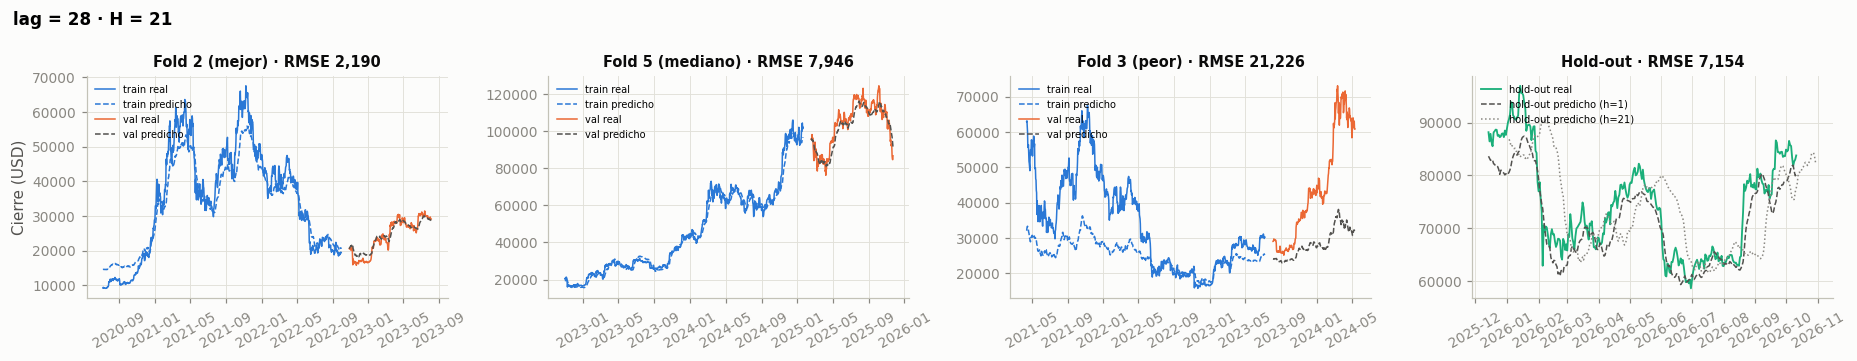

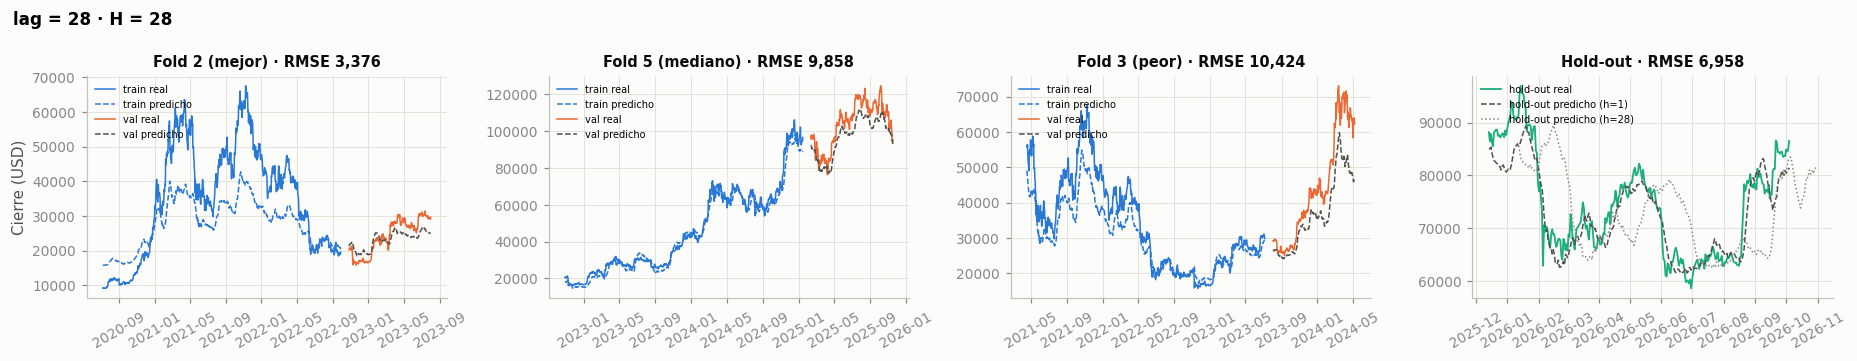

In [6]:
def plot_config(lag, H):
    preds = load_preds(RES / "preds" / f"{FINAL}_lag{lag}_h{H}.npz")
    d = pf.query("estrategia == @FINAL and lag == @lag and H == @H and modelo == 'mlp'").sort_values("RMSE")
    picks = [("mejor", d.fold.iloc[0]), ("mediano", d.fold.iloc[len(d) // 2]), ("peor", d.fold.iloc[-1])]
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.3))
    for ax, (lab, k) in zip(axes, picks):
        p = preds[("mlp", int(k))]
        ti, vi = p["train_idx"], p["val_idx"]
        tail = ti[ti >= vi.min() - 3 * len(vi)]  # tramo de entrenamiento cercano, para que se vea el empalme
        sel = np.isin(ti, tail)
        ax.plot(dates.iloc[ti[sel]], p["y_train"][sel, 0], color=PART_COLOR["train"], lw=1, label="train real")
        ax.plot(dates.iloc[ti[sel]], p["p_train"][sel, 0], color=PART_COLOR["train"], lw=1, ls="--", label="train predicho")
        ax.plot(dates.iloc[vi], p["y_val"][:, 0], color=PART_COLOR["val"], lw=1, label="val real")
        ax.plot(dates.iloc[vi], p["p_val"][:, 0], color=INK2, lw=1, ls="--", label="val predicho")
        rm = d.set_index("fold").loc[k, "RMSE"]
        ax.set_title(f"Fold {k} ({lab}) · RMSE {rm:,.0f}", fontsize=9.5)
        ax.tick_params(axis="x", labelrotation=30)
    res = final[(lag, H)][2]
    ax = axes[3]
    hi = res["hold_idx"]
    ax.plot(dates.iloc[hi], res["y_hold"][:, 0], color=PART_COLOR["hold"], lw=1.2, label="hold-out real")
    ax.plot(dates.iloc[hi], res["p_hold"][:, 0], color=INK2, lw=1, ls="--", label="hold-out predicho (h=1)")
    ax.plot(dates.iloc[hi + H - 1], res["p_hold"][:, -1], color=MUTED, lw=1, ls=":", label=f"hold-out predicho (h={H})")
    ax.set_title(f"Hold-out · RMSE {res['summary_mlp']['RMSE']:,.0f}", fontsize=9.5)
    ax.tick_params(axis="x", labelrotation=30)
    for a in axes:
        a.legend(fontsize=6.5, loc="upper left")
    axes[0].set_ylabel("Cierre (USD)")
    fig.suptitle(f"lag = {lag} · H = {H}", x=0.01, ha="left", fontsize=11, fontweight="bold")
    savefig(fig, FIG, f"05_series_lag{lag}_h{H}")
    plt.show()


for lag in LAGS:
    for H in HS:
        plot_config(lag, H)

In [7]:
dd = dep.assign(gana=dep["RMSE hold-out"] < dep["RMSE ingenuo hold-out"])
display(Markdown(
    f"**Lectura automática.** En el hold-out, el MLP desplegado le gana al pronóstico ingenuo en {int(dd.gana.sum())} de "
    f"{len(dd)} horizontes (RMSE). MAPE del MLP en el hold-out: "
    + ", ".join(f"H={r['H']}: {r['MAPE hold-out']:.2f} %" for _, r in dd.iterrows())
    + ". Si el precio del hold-out supera el rango visto en entrenamiento, un MLP que predice el **nivel** tiende a "
    "quedarse por debajo (no extrapola): el ingenuo, que copia el último valor, no tiene ese problema."))

**Lectura automática.** En el hold-out, el MLP desplegado le gana al pronóstico ingenuo en 0 de 4 horizontes (RMSE). MAPE del MLP en el hold-out: H=7: 6.05 %, H=14: 5.06 %, H=21: 6.17 %, H=28: 7.43 %. Si el precio del hold-out supera el rango visto en entrenamiento, un MLP que predice el **nivel** tiende a quedarse por debajo (no extrapola): el ingenuo, que copia el último valor, no tiene ese problema.